
# Traffic Sign Recognition System

## Student and Team Details

**Team Name:** Team C   
**Team Number:** 03  
**Problem Statement Number:** XV    
**Problem Statement:** Traffic Sign Recognition System

### Team Members

| Sr. No. | Student Name | Student ID | 
|---|---|---|
| 1 | Manasvi Bondre | 24001033 | 
| 2 | Sanobar Pathan | 24001037 | 
| 3 | Shreyal Khobragade | 24001044 | 



**Subject:** Technical Skill Development   
**Faculty Name:** Prof.Rihal Kalbhende    
**Submission Date:** 23 October 2026



## 1. Problem Statement

Traffic sign recognition is an important component of intelligent transportation systems. Recognizing traffic signs automatically can help computer vision systems interpret road-related visual information.

The aim of this project is to develop a Convolutional Neural Network (CNN)-based image classification model that recognizes different categories of Indian traffic signs using labelled images. The project involves image preprocessing, model training, performance evaluation, and developing an application that displays the predicted traffic sign category and confidence score.



## 2. Objectives

The main objective of this project is to develop a CNN-based model for recognizing Indian traffic signs from images. The project aims to collect and prepare a labelled traffic sign dataset, perform image preprocessing, train and evaluate the classification model, analyse its performance using suitable metrics and visualizations, and develop a working application that accepts a traffic sign image and displays the predicted category, confidence score, and corresponding meaning wherever reliable class descriptions are available.


In [3]:

# Import required libraries for Traffic Sign Recognition

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display library versions
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")


NumPy version: 2.0.2
Pandas version: 2.3.3
TensorFlow version: 2.20.0
All libraries imported successfully!


In [4]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: C:\Python39\python.exe -m pip install --upgrade pip


##### import os

project_folders = ["dataset", "model", "results"]

for folder in project_folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

for folder in project_folders:
    print(folder)

In [5]:
# Image processing and model training settings

IMG_HEIGHT = 64
IMG_WIDTH = 64
CHANNELS = 3

BATCH_SIZE = 32
RANDOM_SEED = 42

print("Image height:", IMG_HEIGHT)
print("Image width:", IMG_WIDTH)
print("Color channels:", CHANNELS)
print("Batch size:", BATCH_SIZE)
print("Random seed:", RANDOM_SEED)

Image height: 64
Image width: 64
Color channels: 3
Batch size: 32
Random seed: 42


## 3. Dataset Loading and Preparation

In [6]:
import os
import zipfile

zip_path = "traffic512final.zip"
extract_path = "dataset/traffic_images"

if not os.path.exists(zip_path):
    print("ZIP file not found. Upload it beside your notebook first.")
else:
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Dataset location:", extract_path)

Dataset extracted successfully!
Dataset location: dataset/traffic_images


In [7]:

import os

dataset_path = "dataset/traffic_images"

print("Dataset path:", os.path.abspath(dataset_path))
print("Dataset folder exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Items inside dataset folder:")
    print(os.listdir(dataset_path)[:15])
else:
    print("Dataset folder not found. Check the folder path.")


Dataset path: C:\Users\manas\dataset\traffic_images
Dataset folder exists: True
Items inside dataset folder:
['traffic512final', 'traffic512final.zip', 'traffic_vqa_4341.csv']


In [8]:

import os

extracted_path = os.path.join(dataset_path, "traffic512final")

print("Extracted folder exists:", os.path.exists(extracted_path))
print("\nItems inside extracted folder:")

for item in os.listdir(extracted_path)[:20]:
    item_path = os.path.join(extracted_path, item)
    if os.path.isdir(item_path):
        print(f"[Folder] {item}")
    else:
        print(f"[File] {item}")


Extracted folder exists: True

Items inside extracted folder:
[Folder] .ipynb_checkpoints
[File] img_0001.jpg
[File] img_0002.jpg
[File] img_0003.jpg
[File] img_0004.jpg
[File] img_0005.jpg
[File] img_0006.jpg
[File] img_0007.jpg
[File] img_0008.jpg
[File] img_0009.jpg
[File] img_0010.jpg
[File] img_0011.jpg
[File] img_0012.jpg
[File] img_0013.jpg
[File] img_0014.jpg
[File] img_0015.jpg
[File] img_0016.jpg
[File] img_0017.jpg
[File] img_0018.jpg
[File] img_0019.jpg


In [9]:

import os
import glob

print("Total JPG images:",
      len(glob.glob(os.path.join(extracted_path, "*.jpg"))))

print("\nCSV files in dataset folder:")
for file in glob.glob(os.path.join(dataset_path, "*.csv")):
    print(file)

print("\nCSV files in extracted folder:")
for file in glob.glob(os.path.join(extracted_path, "*.csv")):
    print(file)


Total JPG images: 1085

CSV files in dataset folder:
dataset/traffic_images\traffic_vqa_4341.csv

CSV files in extracted folder:


In [10]:

import zipfile
import os

zip_path = os.path.join(dataset_path, "traffic512final.zip")

with zipfile.ZipFile(zip_path, "r") as zip_file:
    files = zip_file.namelist()

print("Total files in ZIP:", len(files))
print("\nCSV, JSON, and TXT files found:")

label_files = [
    file for file in files
    if file.lower().endswith((".csv", ".json", ".txt", ".xml"))
]

for file in label_files[:20]:
    print(file)

if not label_files:
    print("No annotation files found in the ZIP.")


Total files in ZIP: 1086

CSV, JSON, and TXT files found:
No annotation files found in the ZIP.


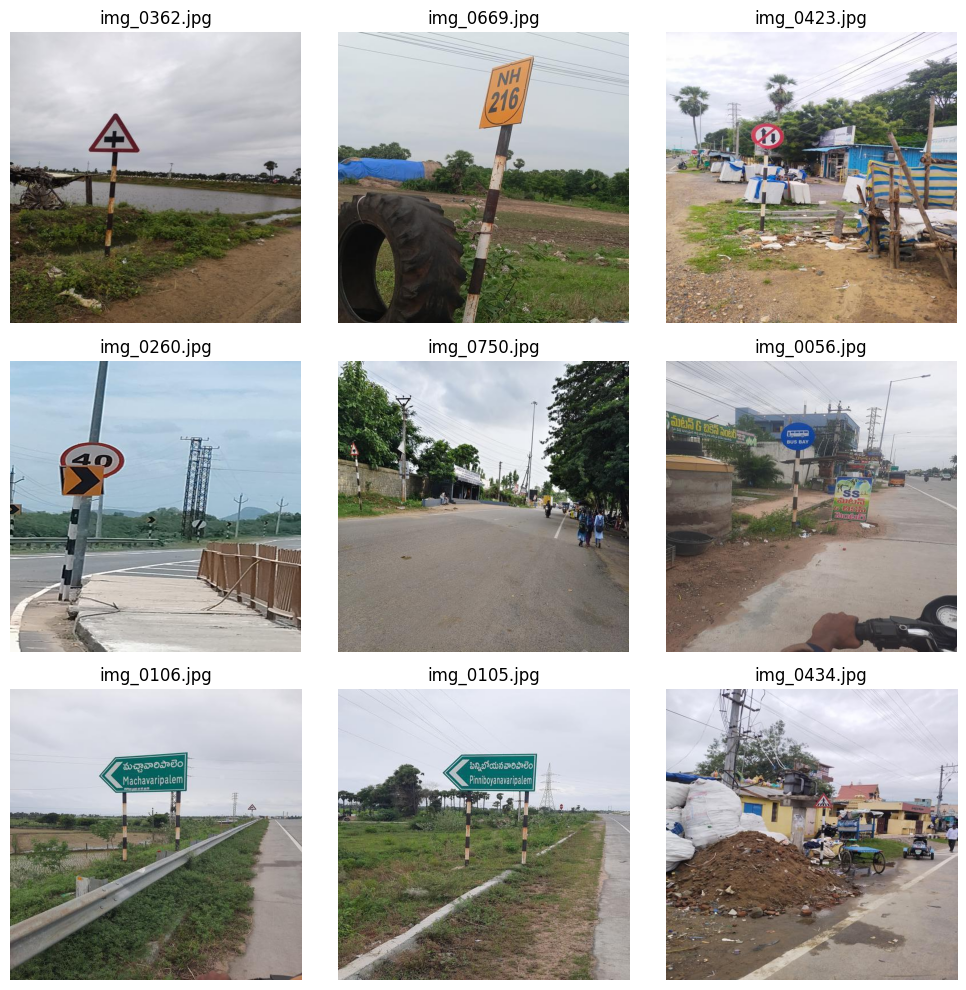

In [11]:

import matplotlib.pyplot as plt
from PIL import Image
import os
import glob
import random

image_files = sorted(
    glob.glob(os.path.join(extracted_path, "*.jpg"))
)

sample_images = random.sample(image_files, min(9, len(image_files)))

plt.figure(figsize=(10, 10))

for i, image_path in enumerate(sample_images):
    image = Image.open(image_path)
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(os.path.basename(image_path))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [12]:

import pandas as pd
import os

csv_path = os.path.join(dataset_path, "traffic_vqa_4341.csv")

if os.path.exists(csv_path):
    annotations = pd.read_csv(csv_path)
    print("CSV shape:", annotations.shape)
    print("\nColumn names:")
    print(annotations.columns.tolist())
    display(annotations.head(10))
else:
    print("CSV not found. Save it inside:", os.path.abspath(dataset_path))


CSV shape: (4341, 5)

Column names:
['id', 'image_name', 'question', 'answer', ' sign']


,id,image_name,question,answer,sign
0,1,img_0001.jpg,What is ahead according to the traffic sign?,Barrier,Cautionary
1,1,img_0001.jpg,What should the driver do?,Slow,Cautionary
2,1,img_0001.jpg,Why is caution needed?,Collision,Cautionary
3,1,img_0001.jpg,Where is this traffic sign usually found?,Tollbooth,Cautionary
4,2,img_0002.jpg,What does this traffic sign indicate?,Barrier,Cautionary
5,2,img_0002.jpg,What type of barrier is mentioned?,Automatic,Cautionary
6,2,img_0002.jpg,Where is this traffic sign usually found?,Toll,Cautionary
7,2,img_0002.jpg,What should the driver do here?,Slow,Cautionary
8,3,img_0003.jpg,What does this traffic sign indicate?,Pedestrian Crossing Ahead,Cautionary
9,3,img_0003.jpg,What should the driver do?,Slow down,Cautionary


In [13]:

print("Unique sign categories:")
print(annotations[" sign"].value_counts())

print("\nNumber of unique categories:")
print(annotations[" sign"].nunique())

print("\nNumber of unique images in CSV:")
print(annotations["image_name"].nunique())



Unique sign categories:
 sign
Cautionary     1636
Mandatory      1053
Informatory    1012
cautionary      584
Cautionary       52
lnformatory       4
Name: count, dtype: int64

Number of unique categories:
6

Number of unique images in CSV:
1085


In [14]:

# Clean column names by removing extra spaces
annotations.columns = annotations.columns.str.strip()

# Clean category labels
annotations["sign"] = (
    annotations["sign"]
    .str.strip()
    .str.lower()
    .replace({
        "cautionary": "Cautionary",
        "mandatory": "Mandatory",
        "informatory": "Informatory",
        "lnformatory": "Informatory"
    })
)

# Keep one label per image
image_labels = annotations[["image_name", "sign"]].drop_duplicates()

# Check whether any image has conflicting labels
label_counts = image_labels.groupby("image_name")["sign"].nunique()
conflicting_images = label_counts[label_counts > 1]

print("Unique categories:")
print(image_labels["sign"].value_counts())

print("\nUnique images:", image_labels["image_name"].nunique())
print("Images with conflicting labels:", len(conflicting_images))

display(image_labels.head(10))


Unique categories:
sign
Cautionary     569
Mandatory      263
Informatory    255
Name: count, dtype: int64

Unique images: 1085
Images with conflicting labels: 2


,image_name,sign
0,img_0001.jpg,Cautionary
4,img_0002.jpg,Cautionary
8,img_0003.jpg,Cautionary
12,img_0004.jpg,Cautionary
16,img_0005.jpg,Cautionary
20,img_0006.jpg,Mandatory
24,img_0007.jpg,Cautionary
28,img_0008.jpg,Cautionary
32,img_0009.jpg,Cautionary
36,img_0010.jpg,Informatory


In [15]:

# Remove images that have more than one category
conflicting_names = conflicting_images.index.tolist()

image_labels = image_labels[
    ~image_labels["image_name"].isin(conflicting_names)
].copy()

# Create the full path for each image
image_labels["image_path"] = image_labels["image_name"].apply(
    lambda name: os.path.join(extracted_path, name)
)

# Keep only images that actually exist
image_labels = image_labels[
    image_labels["image_path"].apply(os.path.isfile)
].reset_index(drop=True)

print("Total valid images:", len(image_labels))
print("\nImages per category:")
print(image_labels["sign"].value_counts())

print("\nMissing image files:",
      (~image_labels["image_path"].apply(os.path.isfile)).sum())

display(image_labels.head())


Total valid images: 1083

Images per category:
sign
Cautionary     567
Mandatory      263
Informatory    253
Name: count, dtype: int64

Missing image files: 0


,image_name,sign,image_path
0,img_0001.jpg,Cautionary,dataset/traffic_images\traffic512final\img_000...
1,img_0002.jpg,Cautionary,dataset/traffic_images\traffic512final\img_000...
2,img_0003.jpg,Cautionary,dataset/traffic_images\traffic512final\img_000...
3,img_0004.jpg,Cautionary,dataset/traffic_images\traffic512final\img_000...
4,img_0005.jpg,Cautionary,dataset/traffic_images\traffic512final\img_000...


In [16]:

import numpy as np
from PIL import Image

images = []
labels = []

# Convert category names into numerical labels
class_names = ["Cautionary", "Informatory", "Mandatory"]
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

for _, row in image_labels.iterrows():
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        img = img.resize((IMG_WIDTH, IMG_HEIGHT))

        images.append(np.array(img))
        labels.append(class_to_index[row["sign"]])

    except Exception as e:
        print("Error loading:", row["image_name"], e)

X = np.array(images, dtype=np.uint8)
y = np.array(labels, dtype=np.int32)

print("Images array shape:", X.shape)
print("Labels array shape:", y.shape)
print("Classes:", class_names)
print("Images loaded successfully:", len(X))


Images array shape: (1083, 64, 64, 3)
Labels array shape: (1083,)
Classes: ['Cautionary', 'Informatory', 'Mandatory']
Images loaded successfully: 1083


In [17]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels distribution:")
for index, name in enumerate(class_names):
    print(f"{name}: {np.sum(y_train == index)}")

print("\nTesting labels distribution:")
for index, name in enumerate(class_names):
    print(f"{name}: {np.sum(y_test == index)}")


Training images: 866
Testing images: 217

Training data shape: (866, 64, 64, 3)
Testing data shape: (217, 64, 64, 3)

Training labels distribution:
Cautionary: 454
Informatory: 202
Mandatory: 210

Testing labels distribution:
Cautionary: 113
Informatory: 51
Mandatory: 53


## 4. CNN Model Building

In [18]:

from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),
    
    layers.Rescaling(1.0 / 255),
    
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    
    # Three traffic sign categories
    layers.Dense(3, activation="softmax")
])

cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 683,587 (2.61 MB)

 Trainable params: 683,587 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Model Compilation

In [19]:

# Compile the CNN model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")
print("Optimizer: Adam")
print("Loss function: Sparse Categorical Crossentropy")
print("Evaluation metric: Accuracy")


CNN model compiled successfully!
Optimizer: Adam
Loss function: Sparse Categorical Crossentropy
Evaluation metric: Accuracy


## 6. Model Training Configuration

In [20]:

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np

# Calculate class weights from the training labels
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

# Train the improved CNN
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = cnn_model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Class weights: {0: 0.6358296622613803, 1: 1.4290429042904291, 2: 1.3746031746031746}
Epoch 1/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 111ms/step - accuracy: 0.3085 - loss: 1.1349 - val_accuracy: 0.3506 - val_loss: 1.0957 - learning_rate: 0.0010
Epoch 2/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - accuracy: 0.4043 - loss: 1.1022 - val_accuracy: 0.2011 - val_loss: 1.1460 - learning_rate: 0.0010
Epoch 3/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.4007 - loss: 1.0449 - val_accuracy: 0.3506 - val_loss: 1.0618 - learning_rate: 0.0010
Epoch 4/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.4925 - loss: 0.9242 - val_accuracy: 0.6264 - val_loss: 0.8946 - learning_rate: 0.0010
Epoch 5/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.6220 - loss: 0.8969 - val_accuracy: 0.6264 - val_loss: 0.8827 - learning_rate: 0.0010
Epoch 6/25
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.5323 - loss: 0.9242 - val_accuracy: 0.6322 - val_loss: 0.8349 - learning_rate: 0.0010
Epoch 7/

## 7. Training Performance Visualization

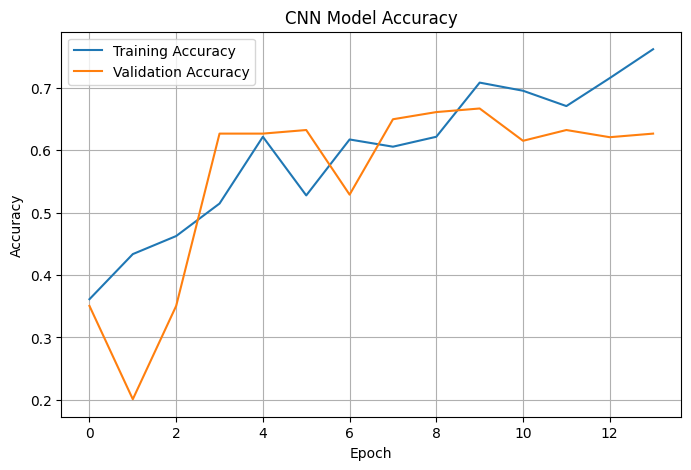

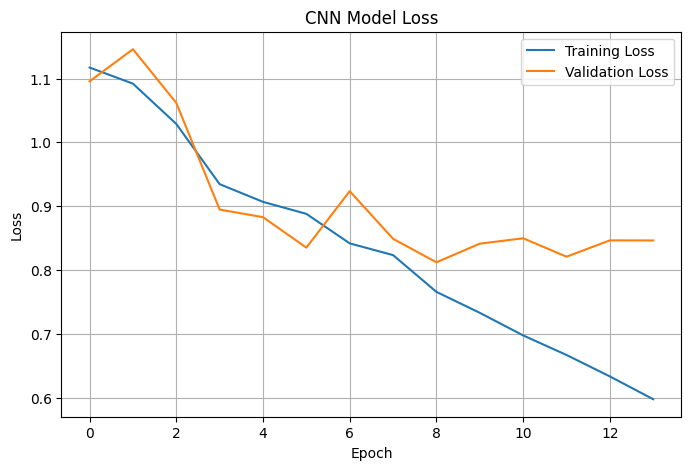

In [21]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


## 8. Data Visualization

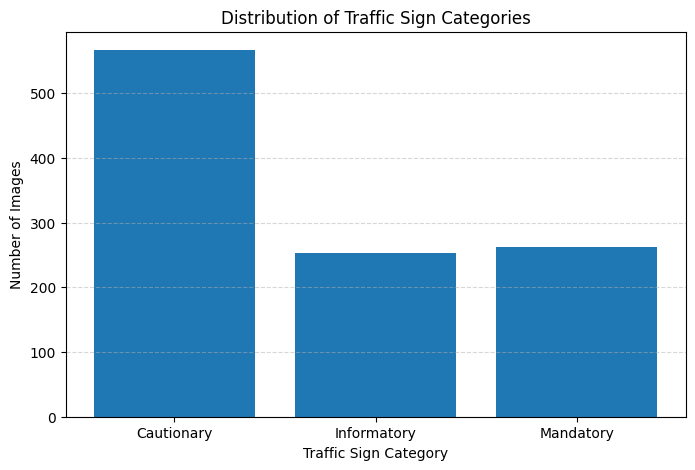

In [22]:

# Visualize the distribution of traffic sign categories
class_counts = [
    np.sum(y == index) for index in range(len(class_names))
]

plt.figure(figsize=(8, 5))
plt.bar(class_names, class_counts)
plt.title("Distribution of Traffic Sign Categories")
plt.xlabel("Traffic Sign Category")
plt.ylabel("Number of Images")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


## 9. Model Evaluation

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Test Accuracy: 63.59%

Classification Report:
              precision    recall  f1-score   support

  Cautionary       0.69      0.83      0.75       113
 Informatory       0.70      0.61      0.65        51
   Mandatory       0.36      0.25      0.29        53

    accuracy                           0.64       217
   macro avg       0.58      0.56      0.57       217
weighted avg       0.61      0.64      0.62       217



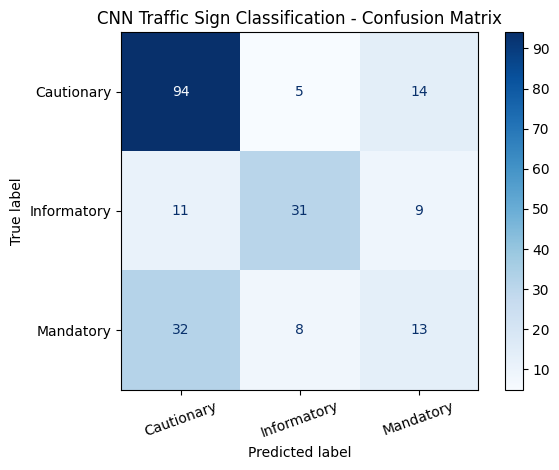

In [23]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict classes for test images
y_prob = cnn_model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(cmap="Blues", values_format="d")
plt.title("CNN Traffic Sign Classification - Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [24]:
print("Current model:", type(cnn_model).__name__)
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Classes:", class_names)

Current model: Sequential
Training images: (866, 64, 64, 3)
Testing images: (217, 64, 64, 3)
Classes: ['Cautionary', 'Informatory', 'Mandatory']


In [25]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("class_names exists:", "class_names" in globals())
print("transfer_model exists:", "transfer_model" in globals())

X_train exists: True
X_test exists: True
class_names exists: True
transfer_model exists: False



###  10. Image Resizing for Transfer Learning

The images are resized to 160 × 160 pixels to prepare them for the MobileNetV2 transfer learning model.


In [26]:

import tensorflow as tf
import numpy as np

IMG_SIZE_TRANSFER = 160

X_train_transfer = tf.image.resize(
    X_train, (IMG_SIZE_TRANSFER, IMG_SIZE_TRANSFER)
)

X_test_transfer = tf.image.resize(
    X_test, (IMG_SIZE_TRANSFER, IMG_SIZE_TRANSFER)
)

print("Training images:", X_train_transfer.shape)
print("Testing images:", X_test_transfer.shape)


Training images: (866, 160, 160, 3)
Testing images: (217, 160, 160, 3)



### 11. MobileNetV2 Model Building

MobileNetV2 is a pre-trained convolutional neural network used for transfer learning. It extracts useful image features and helps improve classification performance on smaller datasets.


In [27]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Load the pre-trained MobileNetV2 model
base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pre-trained layers
base_model.trainable = False

# Build the transfer learning model
transfer_model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    layers.Rescaling(scale=1/127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

transfer_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 47s 5us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


###  12. Model Compilation

The MobileNetV2 transfer learning model is compiled using the Adam optimizer and sparse categorical cross-entropy loss function to classify traffic signs into three categories.


In [28]:

from tensorflow.keras.optimizers import Adam

transfer_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully!")


MobileNetV2 model compiled successfully!



### 13. Training the MobileNetV2 Model

The model is trained using the training dataset with class weights to handle class imbalance. Early stopping and learning rate reduction are used to improve training and reduce overfitting.


In [29]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights_transfer = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

# Training callbacks
early_stop_transfer = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr_transfer = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

# Train the model
history_transfer = transfer_model.fit(
    X_train_transfer,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_transfer,
    callbacks=[early_stop_transfer, reduce_lr_transfer],
    verbose=1
)


Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 18s 529ms/step - accuracy: 0.3929 - loss: 1.4617 - val_accuracy: 0.6322 - val_loss: 0.8193 - learning_rate: 5.0000e-04
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 411ms/step - accuracy: 0.6938 - loss: 0.7397 - val_accuracy: 0.7356 - val_loss: 0.6330 - learning_rate: 5.0000e-04
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 401ms/step - accuracy: 0.7491 - loss: 0.6644 - val_accuracy: 0.6954 - val_loss: 0.6944 - learning_rate: 5.0000e-04
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 394ms/step - accuracy: 0.7854 - loss: 0.5100 - val_accuracy: 0.7356 - val_loss: 0.6164 - learning_rate: 5.0000e-04
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 402ms/step - accuracy: 0.8108 - loss: 0.4800 - val_accuracy: 0.7471 - val_loss: 0.5784 - learning_rate: 5.0000e-04
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 403ms/step - accuracy: 0.8229 - loss: 0.4605 - val_accuracy: 0.7586 - val_loss: 0.5612 - learning_rate: 5.0000e-04
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 406ms/step - accuracy:


###  14. Training and Validation Performance Visualization

The training and validation accuracy and loss are plotted to observe model learning, convergence, and possible overfitting.


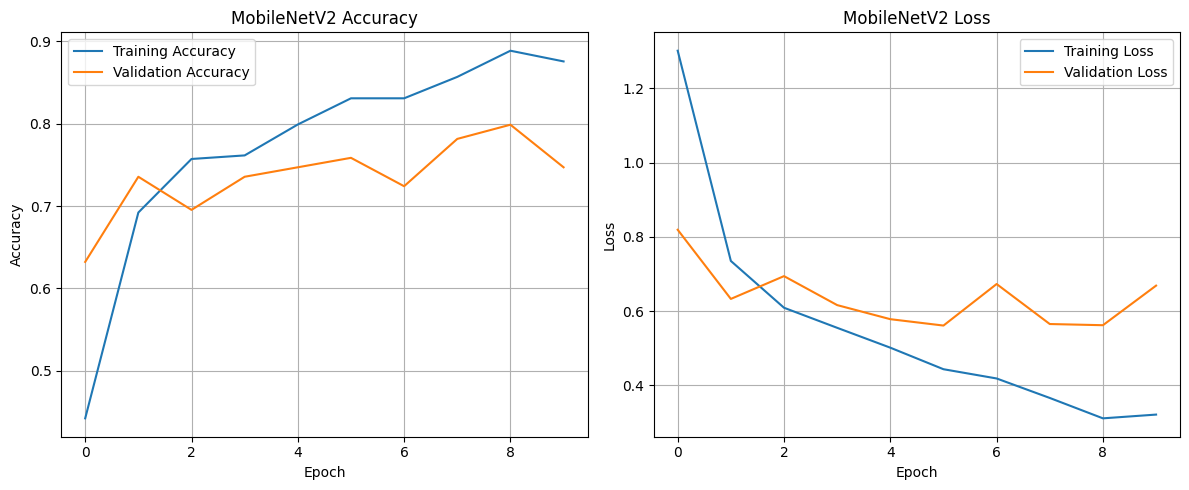

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_transfer.history["accuracy"], label="Training Accuracy")
plt.plot(history_transfer.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_transfer.history["loss"], label="Training Loss")
plt.plot(history_transfer.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



###  15. Model Evaluation

The trained MobileNetV2 model is evaluated on the test dataset to measure its classification accuracy and generalization performance on unseen images.


In [32]:

from sklearn.metrics import accuracy_score, classification_report

# Predict test images
y_pred_prob = transfer_model.predict(X_test_transfer)
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"MobileNetV2 Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))


7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 586ms/step
MobileNetV2 Test Accuracy: 70.05%

Classification Report:

              precision    recall  f1-score   support

  Cautionary       0.80      0.76      0.78       113
 Informatory       0.63      0.75      0.68        51
   Mandatory       0.56      0.53      0.54        53

    accuracy                           0.70       217
   macro avg       0.67      0.68      0.67       217
weighted avg       0.70      0.70      0.70       217




###  16. Fine-Tuning MobileNetV2

The final layers of the pre-trained MobileNetV2 model are fine-tuned using a low learning rate to adapt the extracted features to the traffic sign dataset.


In [33]:

# Unfreeze the pretrained model for fine-tuning
base_model.trainable = True

# Freeze earlier layers and fine-tune only the final layers
for layer in base_model.layers[:100]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable training
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a low learning rate
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))


Fine-tuning model compiled successfully!
Trainable layers: 36



###  17. Fine-Tuning Training

The model is fine-tuned with a low learning rate to adapt pretrained image features to the traffic sign categories while monitoring validation loss to reduce overfitting.


In [34]:

fine_tune_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001
)

history_finetune = transfer_model.fit(
    X_train_transfer,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_transfer,
    callbacks=[fine_tune_early_stop, fine_tune_reduce_lr],
    verbose=1
)


Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 25s 683ms/step - accuracy: 0.8639 - loss: 0.3600 - val_accuracy: 0.7529 - val_loss: 0.5717 - learning_rate: 1.0000e-05
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 580ms/step - accuracy: 0.8743 - loss: 0.3272 - val_accuracy: 0.7471 - val_loss: 0.5831 - learning_rate: 1.0000e-05
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 509ms/step - accuracy: 0.8928 - loss: 0.2716 - val_accuracy: 0.7644 - val_loss: 0.5536 - learning_rate: 1.0000e-05
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 523ms/step - accuracy: 0.9166 - loss: 0.2272 - val_accuracy: 0.7931 - val_loss: 0.5431 - learning_rate: 1.0000e-05
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 575ms/step - accuracy: 0.9178 - loss: 0.2340 - val_accuracy: 0.8046 - val_loss: 0.5241 - learning_rate: 1.0000e-05
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 567ms/step - accuracy: 0.9216 - loss: 0.2045 - val_accuracy: 0.7471 - val_loss: 0.5773 - learning_rate: 1.0000e-05
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 519ms/step - acc


###  18. Fine-Tuning Performance Analysis

The fine-tuned MobileNetV2 model is analyzed using training and validation metrics to identify its best validation performance.


In [35]:

best_epoch = np.argmax(history_finetune.history["val_accuracy"]) + 1
best_val_accuracy = max(history_finetune.history["val_accuracy"])

print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Final training accuracy: {history_finetune.history['accuracy'][-1] * 100:.2f}%")
print(f"Final validation accuracy: {history_finetune.history['val_accuracy'][-1] * 100:.2f}%")


Best epoch: 10
Best validation accuracy: 83.91%
Final training accuracy: 94.65%
Final validation accuracy: 83.91%



###  19. Saving the Trained Model

The fine-tuned MobileNetV2 model is saved in the native Keras format for future evaluation and integration into the traffic sign recognition application.


In [36]:

import os

os.makedirs("model", exist_ok=True)

model_path = os.path.join("model", "traffic_sign_mobilenetv2.keras")
transfer_model.save(model_path)

print("Model saved successfully at:", model_path)


Model saved successfully at: model\traffic_sign_mobilenetv2.keras


###  20. Evaluate the Fine-Tuned Model

In [37]:
# Evaluate the fine-tuned MobileNetV2 model

from sklearn.metrics import accuracy_score, classification_report

y_pred_prob_finetune = transfer_model.predict(X_test_transfer)
y_pred_finetune = np.argmax(y_pred_prob_finetune, axis=1)

test_accuracy_finetune = accuracy_score(y_test, y_pred_finetune)

print("Fine-Tuned MobileNetV2 Test Accuracy:",
      round(test_accuracy_finetune * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_finetune,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 627ms/step
Fine-Tuned MobileNetV2 Test Accuracy: 79.26 %

Classification Report:

              precision    recall  f1-score   support

  Cautionary       0.85      0.85      0.85       113
 Informatory       0.71      0.82      0.76        51
   Mandatory       0.76      0.64      0.69        53

    accuracy                           0.79       217
   macro avg       0.77      0.77      0.77       217
weighted avg       0.79      0.79      0.79       217



In [38]:
import os

print("Notebook's current folder:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())


Notebook's current folder:
C:\Users\manas

Files and folders:
['.arduinoIDE', '.bash_history', '.cache', '.codex', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.lesshst', '.matplotlib', '.redhat', '.venv', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'C++', 'Contacts', 'Cookies', 'data', 'dataset', 'dataset_source.txt', 'deliveries.csv', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'ManasviBondre_24001033_PS1.ipynb', 'matches.csv', 'model', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{7fdb0611-3ce9-11f1-9686-9af599027b67}.TM.blf', 'NTUSER.DAT{7fdb0611-3ce9-11f1-9686-9af599027b67}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{7fdb0611-3ce9-11f1-9686-9af599027b67}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Penguin.ipynb', 'PrintHood', 'Recent', 'results', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'TeamC_03_PS15.i